# 03 · A carga que vai para Santos fora do trilho

**Para quem:** a área comercial e de planejamento de uma ferrovia que chega a Santos.

**Como:** para açúcar, soja, farelo de soja, milho e celulose, compara o que o Porto de Santos exportou (Comex Stat, por mês, UF de produção e porto) com o que chegou de trem às estações a até 30 km do porto (SIADE, de qualquer concessionária). A diferença é a carga que chegou por outro meio; para esses produtos em Santos, na prática, caminhão.

Tudo vem dos marts `fct_porto_produto_mensal` e `fct_porto_produto_uf_anual`, e o teste `assert_trilho_nao_passa_da_exportacao` garante que as duas fontes conversam: num ano, o trem não traz mais que 110% do que o porto exportou.

In [1]:
import sys; sys.path.insert(0, ".")
from comum import *
mensal = sql("select * from marts.fct_porto_produto_mensal where porto = 'Santos'")
mensal["mes"] = pd.to_datetime(mensal.mes)
mensal["ano"] = mensal.mes.dt.year
anual = mensal[mensal.ano <= 2025].groupby(["ano", "produto"])[["exportado_t", "trilho_t", "fora_do_trilho_t"]].sum()

## Pergunta 1. Quanto das exportações por Santos chega de trem?

In [2]:
a2025 = anual.loc[2025].assign(pct_trilho=lambda t: 100 * t.trilho_t / t.exportado_t)
(a2025.sort_values("fora_do_trilho_t", ascending=False) / [1e6, 1e6, 1e6, 1]).round(1).rename(
    columns={"exportado_t": "exportado (mi t)", "trilho_t": "de trem (mi t)", "fora_do_trilho_t": "fora do trilho (mi t)", "pct_trilho": "% de trem"})

,exportado (mi t),de trem (mi t),fora do trilho (mi t),% de trem
produto,,,,
Soja,34.6,21.9,12.6,63.4
Açúcar,23.5,11.9,11.6,50.6
Milho,14.7,11.9,2.8,80.9
Farelo de soja,10.0,7.4,2.6,73.9
Celulose,9.7,8.3,1.4,85.9


**Resposta (2025):** das 92,4 mi t exportadas por Santos nesses cinco produtos, 61,4 mi t chegaram de trem (66%) e **31,0 mi t chegaram por fora do trilho**. A maior parte está em dois produtos: **soja, com 12,6 mi t**, e **açúcar, com 11,6 mi t**. No açúcar, só 51% chega de trem.

## Pergunta 2. A fatia do trem está crescendo?

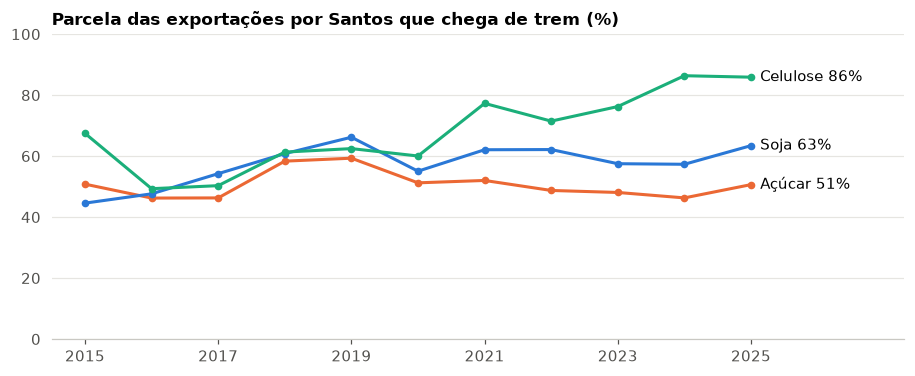

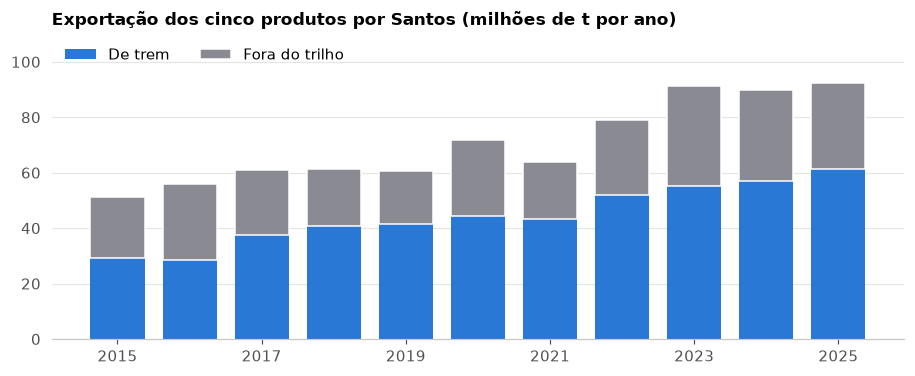

ano,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
exportado_t,51.2,56.0,61.0,61.4,60.7,71.7,64.0,78.9,91.4,90.0,92.4
trilho_t,29.1,28.4,37.5,40.8,41.5,44.3,43.3,51.8,55.2,56.9,61.4
fora_do_trilho_t,22.0,27.6,23.6,20.6,19.2,27.4,20.7,27.0,36.2,33.1,31.0


In [3]:
pct = (anual.trilho_t / anual.exportado_t * 100).unstack()
fig, ax = plt.subplots()
for nome, cor in [("Açúcar", LARANJA), ("Soja", AZUL), ("Celulose", VERDE)]:
    ax.plot(pct.index, pct[nome], color=cor, linewidth=2, marker="o", markersize=4)
    ax.annotate(f"{nome} {pct[nome].iloc[-1]:.0f}%", (pct.index[-1], pct[nome].iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center")
ax.set_xlim(2014.5, 2027.3); ax.set_ylim(0, 100); ax.set_xticks(range(2015, 2026, 2))
ax.set(title="Parcela das exportações por Santos que chega de trem (%)")
plt.show()

total = anual.groupby("ano").sum()
fig, ax = plt.subplots()
ax.bar(total.index, total.trilho_t, color=AZUL, width=0.75, label="De trem")
ax.bar(total.index, total.fora_do_trilho_t, bottom=total.trilho_t, color=CINZA, width=0.75, label="Fora do trilho", edgecolor="white", linewidth=1)
milhoes(ax); ax.set_xticks(range(2015, 2026, 2)); ax.legend(loc="upper left", ncols=2)
ax.set(title="Exportação dos cinco produtos por Santos (milhões de t por ano)", ylim=(0, 110e6))
plt.show()
(total[["exportado_t", "trilho_t", "fora_do_trilho_t"]] / 1e6).round(1).T

**Resposta:** sim, mas não o bastante para diminuir a carga fora do trilho.
- **O porto cresceu mais rápido que tudo:** a exportação dos cinco produtos por Santos foi de 51,2 mi t em 2015 para 92,4 mi t em 2025 (+80%).
- **O trem cresceu mais que o porto:** de 29,1 para 61,4 mi t (+111%), e a parcela dele subiu de 57% para 66%.
- **Mesmo assim, sobrou mais carga fora:** o que chega por fora do trilho foi de 22,0 para 31,0 mi t, com pico de 36,2 mi t em 2023.
- **Por produto:** a **celulose** foi de 67% para 86% de trem. O **açúcar** ficou entre 46% e 59% nos 11 anos, sem tendência.

## Pergunta 3. A carga escapa o ano todo ou só no pico da safra?

Se o trem perde carga só no pico, falta capacidade. Se perde o ano todo, o problema é preço, serviço ou acesso ao trilho. A resposta muda o que a empresa deveria fazer.

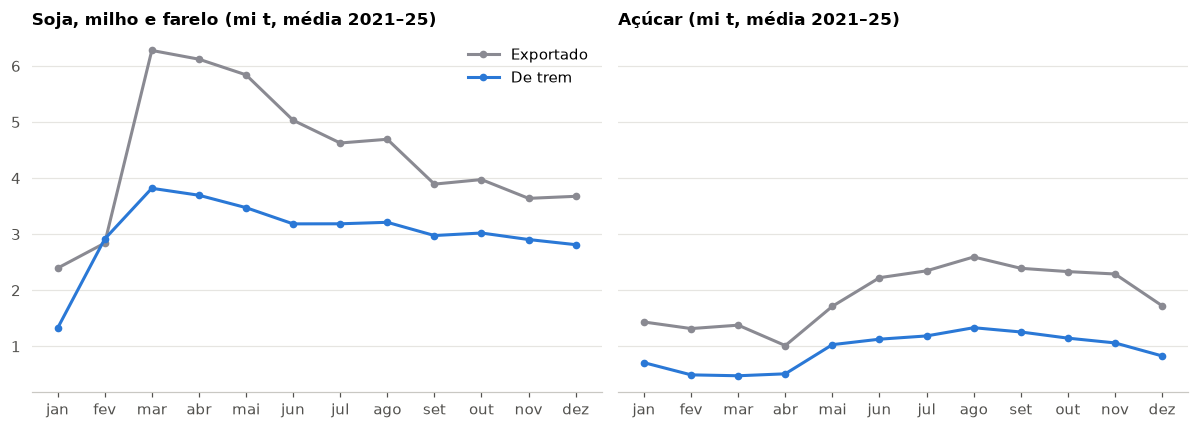

mes                   1     2     3     4     5     6     7     8     9   \
grãos  exportado_t  2.39  2.84  6.28  6.12  5.84  5.03  4.63  4.69  3.89   
       trilho_t     1.32  2.91  3.82  3.69  3.47  3.18  3.19  3.21  2.98   
açúcar exportado_t  1.43  1.32  1.38  1.01  1.71  2.22  2.35  2.59  2.39   
       trilho_t     0.71  0.49  0.47  0.51  1.03  1.13  1.19  1.33  1.26   

mes                   10    11    12  
grãos  exportado_t  3.97  3.64  3.68  
       trilho_t     3.02  2.90  2.81  
açúcar exportado_t  2.33  2.29  1.72  
       trilho_t     1.15  1.06  0.83

In [4]:
graos = mensal[mensal.produto.isin(["Soja", "Milho", "Farelo de soja"]) & mensal.ano.between(2021, 2025)].groupby("mes")[["exportado_t", "trilho_t"]].sum()
perfil = graos.groupby(graos.index.month).mean()
acucar = mensal[(mensal.produto == "Açúcar") & mensal.ano.between(2021, 2025)].groupby(mensal.mes.dt.month)[["exportado_t", "trilho_t"]].mean()
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, dados, titulo in [(a1, perfil, "Soja, milho e farelo"), (a2, acucar, "Açúcar")]:
    ax.plot(range(1, 13), dados.exportado_t, color=CINZA, linewidth=2, marker="o", markersize=4, label="Exportado")
    ax.plot(range(1, 13), dados.trilho_t, color=AZUL, linewidth=2, marker="o", markersize=4, label="De trem")
    ax.set_xticks(range(1, 13), MESES); milhoes(ax); ax.set(title=f"{titulo} (mi t, média 2021–25)")
a1.legend(loc="upper right"); plt.tight_layout(); plt.show()
(pd.concat({"grãos": perfil, "açúcar": acucar}, axis=1) / 1e6).round(2).T

**Resposta: depende do produto, e a diferença é o achado mais útil desta análise.**

- **Grãos: falta capacidade no pico.** O trem entrega de 2,8 a 3,8 mi t de grãos por mês **quase o ano inteiro**, enquanto a exportação vai de 2,4 mi t em janeiro a 6,3 mi t em março. O trilho fica plano e a exportação sobe, então o excesso do pico (março a junho) vai de caminhão. Em julho, o trem cai para 0,8 mi t de soja e sobe para 1,7 mi t de milho: a ferrovia troca de grão sem aumentar o total.
- **O teto sobe, mas o pico sobe junto:** o melhor mês do trem foi de 1,8 mi t em 2015 para 4,2 mi t em 2025, e o melhor mês da exportação foi de 4,2 para 7,1 mi t.
- **Açúcar: não é o pico.** A parcela do trem fica perto de 50% na safra e fora dela. Em fevereiro e março, na entressafra, cai para 34% a 37%. Falta de capacidade explicaria uma queda no pico, e não é o que acontece. O caminho para o açúcar é comercial: preço, terminais e acesso das usinas ao trilho.

## Pergunta 4. De onde vem a carga que vai fora do trilho?

In [5]:
uf = sql("select * from marts.fct_porto_produto_uf_anual where porto = 'Santos' and ano = 2025")
uf["fora_do_trilho_t"] = uf.exportado_t - uf.trilho_t
(uf[uf.fora_do_trilho_t > 5e5].sort_values("fora_do_trilho_t", ascending=False)[["produto", "uf", "exportado_t", "trilho_t", "fora_do_trilho_t"]]
 .assign(exportado_t=lambda t: t.exportado_t / 1e6, trilho_t=lambda t: t.trilho_t / 1e6, fora_do_trilho_t=lambda t: t.fora_do_trilho_t / 1e6).round(1).reset_index(drop=True))

,produto,uf,exportado_t,trilho_t,fora_do_trilho_t
0,Açúcar,SP,17.1,9.1,7.9
1,Soja,GO,9.5,3.2,6.3
2,Soja,MT,14.8,10.6,4.2
3,Soja,SP,3.6,1.3,2.3
4,Açúcar,MG,4.5,2.3,2.2
5,Milho,MT,9.1,6.9,2.1
6,Açúcar,GO,1.3,0.0,1.3
7,Celulose,MS,6.3,5.0,1.3
8,Milho,GO,4.0,3.1,0.9
9,Farelo de soja,GO,2.3,1.6,0.7


**Resposta (2025, aproximada):** os maiores volumes fora do trilho são:
- **açúcar de São Paulo: 7,9 mi t**, com 17,1 mi t exportadas e 9,1 mi t de trem;
- **soja de Goiás: 6,3 mi t**;
- **soja de Mato Grosso: 4,2 mi t**.

É uma aproximação por dois motivos. No Comex Stat, a UF é a de produção; no SIADE, é a da estação onde a carga embarcou no trem. Soja de Goiás que vai de caminhão até um terminal ferroviário em Minas aparece como exportação de GO e como trilho de MG. Para o açúcar de São Paulo a distorção é pequena, porque o produto e o embarque ficam no mesmo estado.

## Pergunta 5. Quem leva até Santos a carga que vai de trem?

In [6]:
quem = sql("""
select produto, ferrovia, sum(tu) / 1e6 as mi_t
from intermediate.int_trilho__chegadas_porto
where porto = 'Santos' and mes between '2025-01-01' and '2025-12-01'
group by 1, 2
""").pivot(index="produto", columns="ferrovia", values="mi_t").fillna(0)
(quem.div(quem.sum(axis=1), axis=0) * 100).round(0)

ferrovia,FCA,MRS,RMC,RMN,RMP
produto,,,,,
Açúcar,47.0,24.0,11.0,4.0,14.0
Celulose,0.0,40.0,0.0,60.0,0.0
Farelo de soja,8.0,0.0,0.0,73.0,20.0
Milho,5.0,7.0,0.0,62.0,26.0
Soja,26.0,6.0,0.0,53.0,15.0


**Resposta (2025, % da tonelagem que chega de trem):** a MRS responde por **24% do açúcar**, **40% da celulose**, 6% da soja e 7% do milho. A Rumo Malha Norte lidera em soja (53%), milho (62%), farelo (73%) e celulose (60%), e a FCA lidera no açúcar (47%).

A coluna ferrovia do SIADE é a **concessionária responsável pelo fluxo**, não quem opera cada trecho. Por isso esses números não dizem por qual malha a carga desceu a serra até o porto.

## Pergunta 6. Quanto isso representa?

In [7]:
dist = sql("""
select produto, sum(tku)::numeric / sum(tu) as km_trem
from intermediate.int_trilho__chegadas_porto
where porto = 'Santos' and mes between '2025-01-01' and '2025-12-01'
group by 1
""").set_index("produto").km_trem.astype(float)
pot = a2025.join(dist)
pot["bi_tku_potencial"] = pot.fora_do_trilho_t * pot.km_trem / 1e9
pot["mil_viagens_de_37t"] = pot.fora_do_trilho_t / 37 / 1e3
pot[["fora_do_trilho_t", "km_trem", "bi_tku_potencial", "mil_viagens_de_37t"]].assign(fora_do_trilho_t=lambda t: t.fora_do_trilho_t / 1e6).round(1).sort_values("bi_tku_potencial", ascending=False)

,fora_do_trilho_t,km_trem,bi_tku_potencial,mil_viagens_de_37t
produto,,,,
Soja,12.6,1265.1,16.0,341.8
Açúcar,11.6,681.6,7.9,312.9
Milho,2.8,1395.8,3.9,75.7
Farelo de soja,2.6,1467.6,3.8,70.9
Celulose,1.4,799.6,1.1,36.9


**Resposta (2025, ordem de grandeza):** as 31,0 mi t fora do trilho equivalem a cerca de **840 mil viagens de caminhão**, considerando 37 t por viagem, a carga de um bitrem graneleiro (isso é uma suposição, não um dado). Levadas pela distância média que o trem já faz até Santos em cada produto, seriam cerca de **33 bilhões de TKU**. Para comparar: a MRS inteira produziu 71,7 bilhões de TKU em 2025.

Isso é um teto, não uma previsão. Supõe que a carga fora do trilho viajaria a mesma distância que a do trem, e parte dela vem de perto do porto, onde o caminhão é mais competitivo.

## Limitações

- **Ano corrente:** a comparação usa só os meses que as duas fontes publicaram. Em 2026, o SIADE vai até agosto e o Comex Stat, até setembro.
- **Porto pelo raio:** a chegada ao porto é definida pelas estações a até 30 km dele. Uma estação de pátio industrial dentro do raio só entra se a mercadoria for uma das cinco.
- **Exportação e cabotagem:** carga de trem que chega ao porto para cabotagem, e não para exportação, aparece como trilho sem exportação correspondente. Nesses cinco produtos, o teste de coerência mostra que isso é pequeno.
- **Associação, não causa:** os dados mostram onde a carga está, não por que ela escolheu o caminhão.